# Loan Approval Prediction  
## The project aims to find out that will the loan be approved or not

## Loading Data

In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [81]:
import kagglehub
path = kagglehub.dataset_download("taweilo/loan-approval-classification-data")

Using Colab cache for faster access to the 'loan-approval-classification-data' dataset.


In [82]:
data=pd.read_csv(path + '/loan_data.csv')
df=data.copy()
df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


## Understanding Data

In [83]:
df.shape

(45000, 14)

In [84]:
df.isnull().sum()

,0
person_age,0
person_gender,0
person_education,0
person_income,0
person_emp_exp,0
person_home_ownership,0
loan_amnt,0
loan_intent,0
loan_int_rate,0
loan_percent_income,0


In [85]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  object 
 2   person_education                45000 non-null  object 
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  object 
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  object 
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_loan_defaults_on_file  

In [86]:
df.duplicated().sum()

np.int64(0)

## Outliers Detection

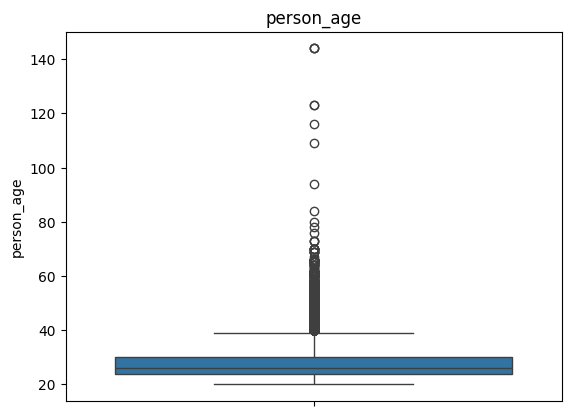

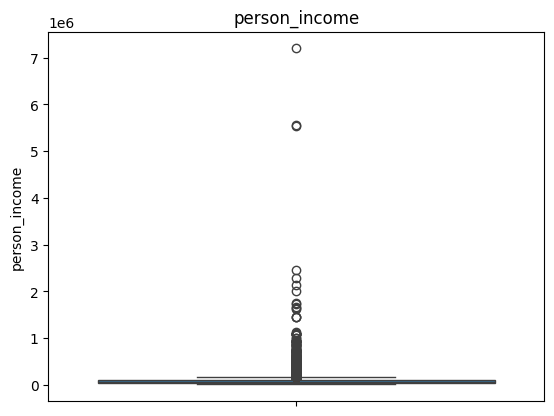

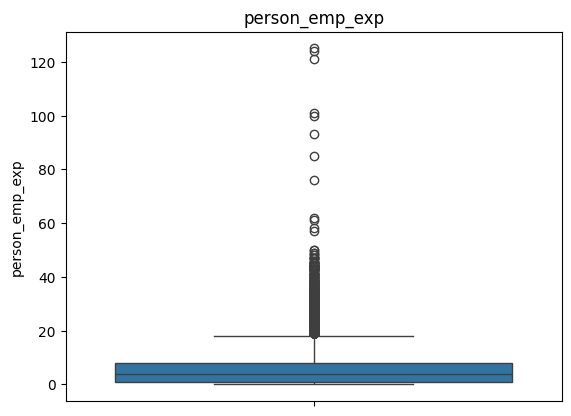

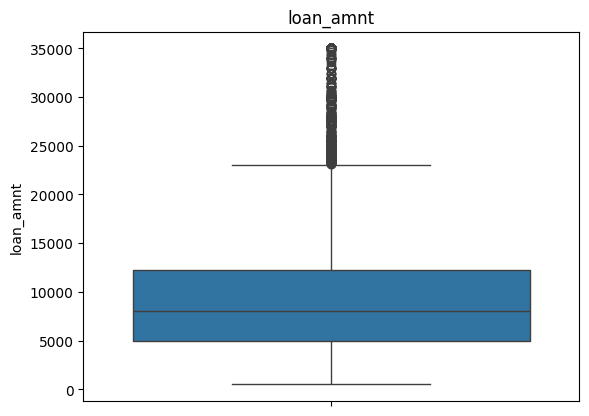

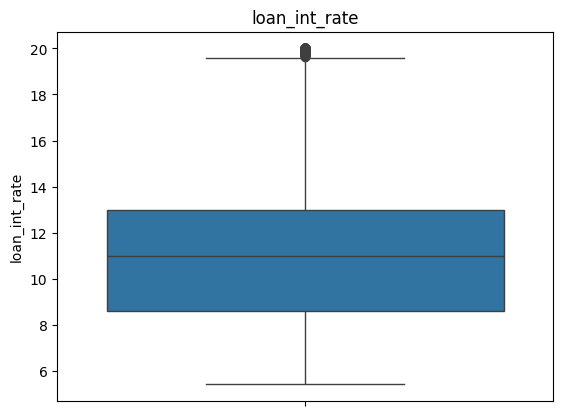

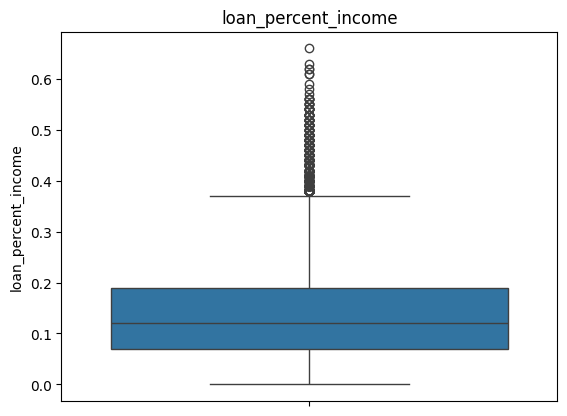

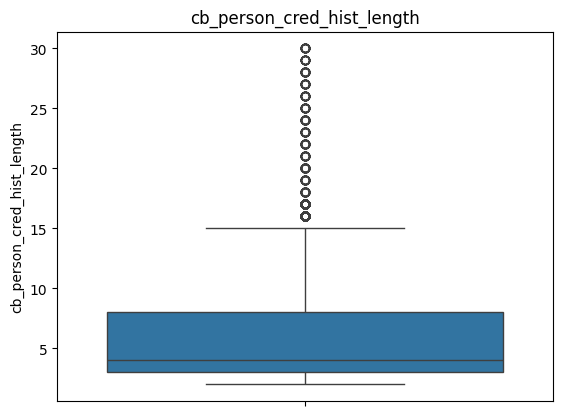

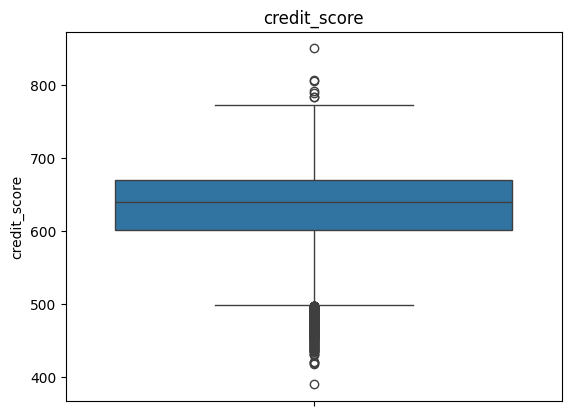

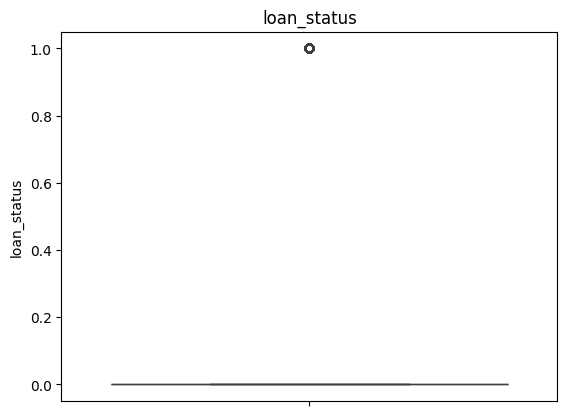

<Figure size 640x480 with 0 Axes>

In [87]:
num_cols=df.select_dtypes(['float64','int64']).columns

for col in num_cols:
  sns.boxplot(df[col])
  plt.title(col)
  plt.show()
plt.savefig('outliers.png')

In [88]:
# for the age column
"""
For home loans, the maximum age at maturity can stretch up to 65 to 70 years, depending on whether you are salaried or self-employed.
so, we would delete the records with age above 70"""
df=df[df['person_age']<=70]
df.shape

(44985, 14)

In [89]:
# person_emp_exp
print(df['person_emp_exp'].value_counts())
""" we can see that experience above 40 years has least number of people so we can clearly remove them"""
df=df[df['person_emp_exp']<=40]
print(df.shape)

person_emp_exp
0     9566
2     4134
1     4061
3     3890
4     3524
5     3000
6     2717
7     2204
8     1890
9     1575
10    1383
11    1148
12     926
13     768
14     662
15     567
16     481
17     413
18     367
19     263
20     240
21     187
22     160
23     133
24     129
25     102
26      97
27      60
28      48
29      43
31      34
30      30
32      29
34      24
35      17
33      15
37      13
44      12
36      10
38       9
43       9
40       8
41       8
39       8
45       7
42       4
47       3
46       2
49       2
50       2
48       1
Name: count, dtype: int64
(44935, 14)


In [90]:
# for cb_credit_history
print(df['cb_person_cred_hist_length'].value_counts())
""" we observe that credit history lenght above 20 has least number of observations so we can delete the observations to reduce extremity"""
df=df[df['cb_person_cred_hist_length']<=20]
print(df.shape)

cb_person_cred_hist_length
4.0     8652
3.0     8310
2.0     6536
5.0     3082
6.0     2966
7.0     2889
8.0     2800
9.0     2685
10.0    2457
12.0     715
11.0     712
14.0     644
13.0     625
15.0     557
16.0     542
17.0     469
20.0      41
18.0      32
22.0      26
19.0      25
28.0      24
24.0      23
23.0      22
30.0      20
21.0      20
26.0      18
27.0      15
25.0      15
29.0      13
Name: count, dtype: int64
(44739, 14)


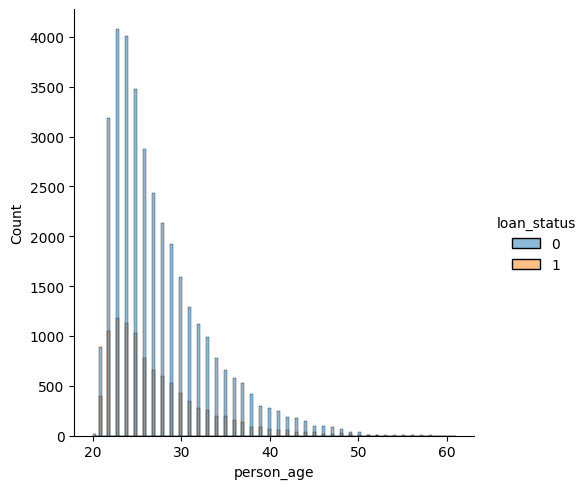

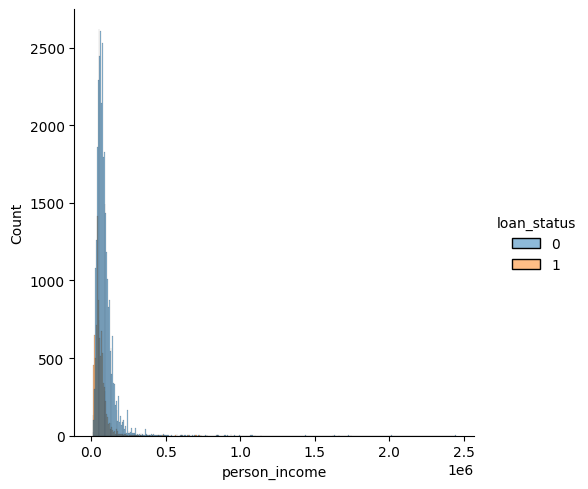

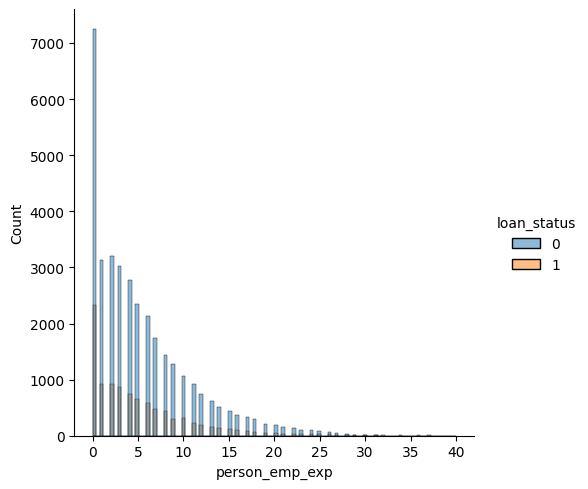

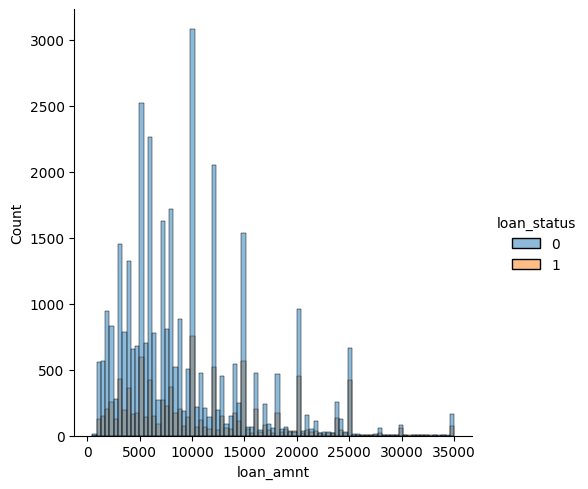

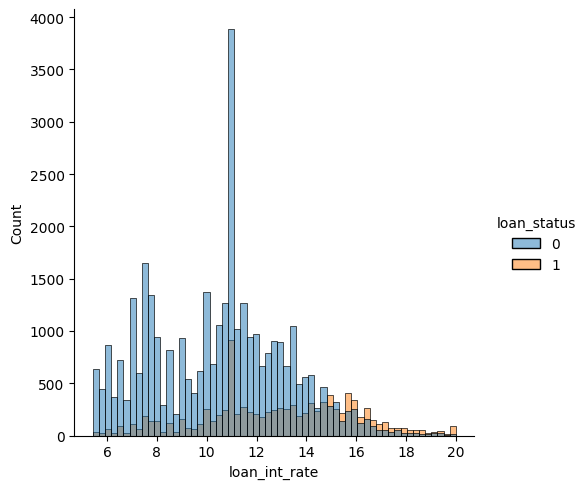

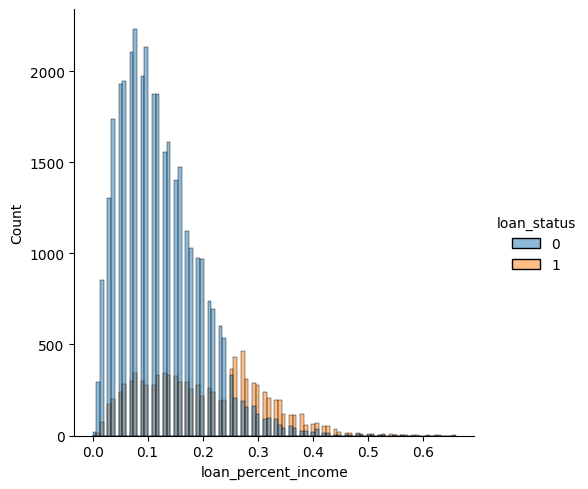

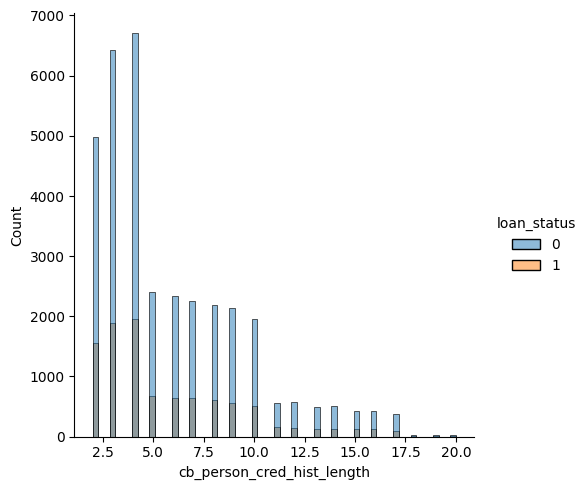

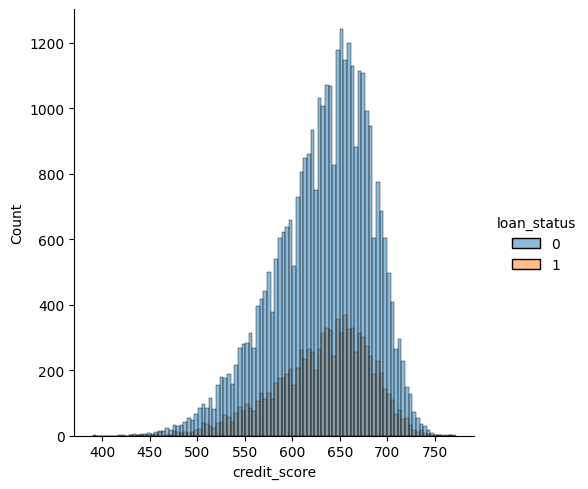

In [91]:
num_list = list(num_cols)
num_list.remove('loan_status')

for i in num_list:
  sns.displot(data=df, x=i, hue='loan_status')
  plt.xlabel(str(i))
  plt.ylabel('Count')
  plt.show()

## Encoding Categorical columns

In [92]:
cat_cols=df.select_dtypes('object').columns
df[cat_cols].head()

,person_gender,person_education,person_home_ownership,loan_intent,previous_loan_defaults_on_file
0,female,Master,RENT,PERSONAL,No
1,female,High School,OWN,EDUCATION,Yes
2,female,High School,MORTGAGE,MEDICAL,No
3,female,Bachelor,RENT,MEDICAL,No
4,male,Master,RENT,MEDICAL,No


One Hot Encoding would be better for binary classes.

In [93]:
encoded=pd.get_dummies(data=df[cat_cols],dtype='int64',drop_first=True) # n-1 encoding
df=pd.concat([df,encoded],axis=1).drop(columns=cat_cols)
df.head()

,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,loan_status,person_gender_male,...,person_education_Master,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,previous_loan_defaults_on_file_Yes
0,22.0,71948.0,0,35000.0,16.02,0.49,3.0,561,1,0,...,1,0,0,1,0,0,0,1,0,0
1,21.0,12282.0,0,1000.0,11.14,0.08,2.0,504,0,0,...,0,0,1,0,1,0,0,0,0,1
2,25.0,12438.0,3,5500.0,12.87,0.44,3.0,635,1,0,...,0,0,0,0,0,0,1,0,0,0
3,23.0,79753.0,0,35000.0,15.23,0.44,2.0,675,1,0,...,0,0,0,1,0,0,1,0,0,0
4,24.0,66135.0,1,35000.0,14.27,0.53,4.0,586,1,1,...,1,0,0,1,0,0,1,0,0,0


## EDA

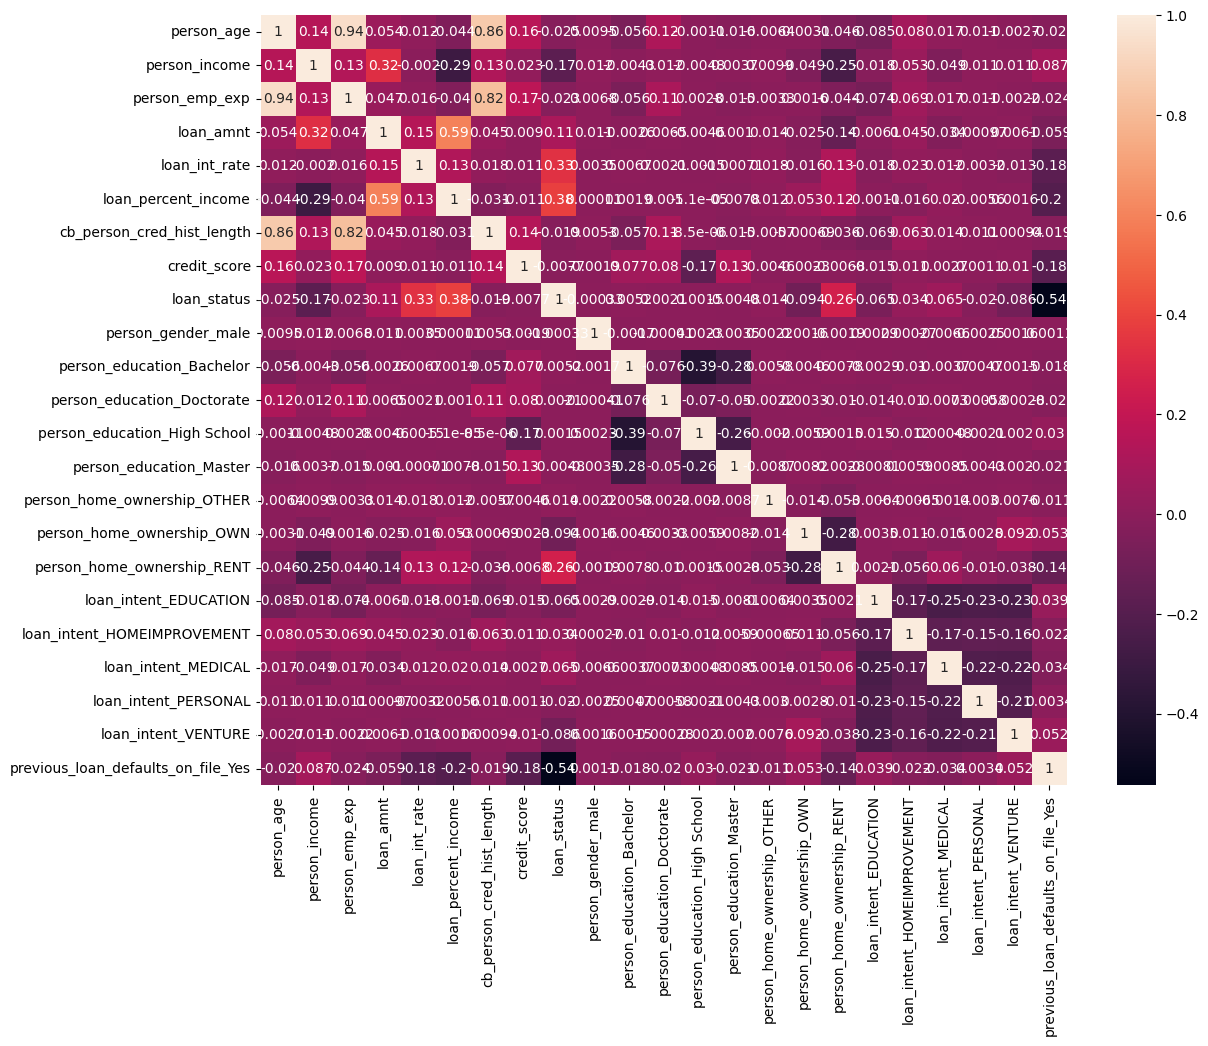

In [95]:
plt.figure(figsize=(13,10))
sns.heatmap(df.corr(),annot=True)
plt.show()

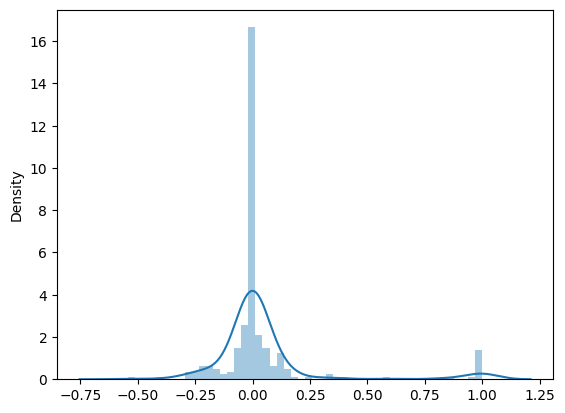

In [97]:
sns.distplot(df.corr())
plt.show()

Correlation concentrated near zero

# Split and Scaling

In [99]:
X=df.drop(columns='loan_status').values
y=df['loan_status']

In [100]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=42)

In [101]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_train=sc.fit_transform(X_train)
X_test=sc.transform(X_test)
X_train

array([[-1.0227767 , -0.93436604, -0.95228641, ..., -0.44849249,
        -0.45995047, -1.01774094],
       [ 0.26146533,  0.24356297,  1.0556268 , ..., -0.44849249,
         2.17414716, -1.01774094],
       [-0.83931355,  0.08083009, -0.22213615, ...,  2.22969172,
        -0.45995047,  0.98256831],
       ...,
       [-0.47238726,  1.06411076, -0.22213615, ..., -0.44849249,
        -0.45995047,  0.98256831],
       [-0.28892411,  2.00509364, -0.58721128, ..., -0.44849249,
         2.17414716, -1.01774094],
       [-0.6558504 ,  2.14583559, -0.40467372, ..., -0.44849249,
         2.17414716,  0.98256831]], shape=(33554, 22))

## Model Training

In [102]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(X_train,y_train)

LogisticRegression()

## Model Evaluation


In [103]:
from sklearn.metrics import confusion_matrix,precision_score,recall_score,accuracy_score

y_pred=model.predict(X_test)

print("Accuracy :",accuracy_score(y_test,y_pred))
print("Precision :",precision_score(y_test,y_pred))
print("Recall :",recall_score(y_test,y_pred))

Accuracy : 0.8986142154671435
Precision : 0.7918060200668896
Recall : 0.7486166007905138


We got the accuracy as 0.89 so we can state that our model performs well.  
Verdict : Good Model

## Graphical representation of confusion matrix

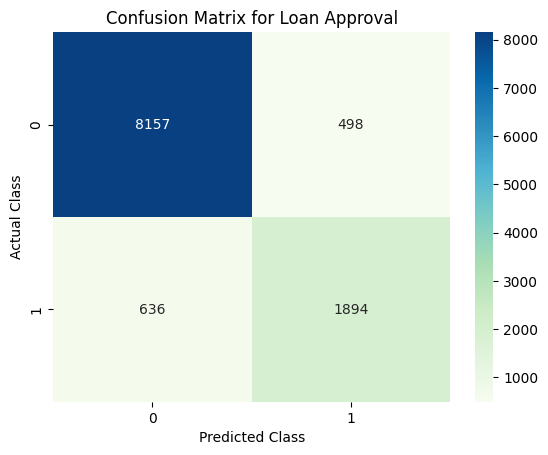

In [116]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='GnBu')
plt.title('Confusion Matrix for Loan Approval')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

Since we have higher numbers of TN(i.e 8157) and TP(i.e 1894) we can say that our model is performing *Good*